In [1]:
%pip install torch torchvision

  Using cached torch-2.14.1-cp313-cp313-win_amd64.whl.metadata (38 kB)
  Using cached torchvision-0.29.1-cp313-cp313-win_amd64.whl.metadata (5.7 kB)
  Using cached filelock-4.2.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
Using cached torch-2.14.1-cp313-cp313-win_amd64.whl (124.1 MB)
Using cached torchvision-0.29.1-cp313-cp313-win_amd64.whl (1.4 MB)
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)
Using cached setuptools-84.2.1-py3-none-any.whl (876 kB)
Using cached filelock-4.2.4-py3-none-any.whl (162 kB)

  Attempting uninstall: setuptools

    Found existing installation: setuptools 75.7.0

    Uninstalling setuptools-75.7.0:

   ---------------------------------------- 0/6 [setuptools]
   ---------------------------------------- 0/6 [setupt


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: W:\PYTHON\python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_json("data/train.json")

In [2]:
band1 = np.stack(train["band_1"].values).reshape(-1, 75, 75)
band2 = np.stack(train["band_2"].values).reshape(-1, 75, 75)

X = np.stack([band1, band2], axis=1).astype(np.float32)
y = train["is_iceberg"].values.astype(np.float32)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (1604, 2, 75, 75)
y shape: (1604,)


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)


X_train: (1283, 2, 75, 75)
X_val: (321, 2, 75, 75)
y_train: (1283,)
y_val: (321,)


In [4]:
mean = X_train.mean(axis=(0, 2, 3), keepdims=True)
std = X_train.std(axis=(0, 2, 3), keepdims=True)

X_train = (X_train - mean) / (std + 1e-8)
X_val = (X_val - mean) / (std + 1e-8)

print("Mean:", X_train.mean(axis=(0, 2, 3)))
print("Std:", X_train.std(axis=(0, 2, 3)))


Mean: [-6.590592e-07 -7.192615e-06]
Std: [1.         0.99999964]


In [5]:
import torch
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train)
)

val_dataset = TensorDataset(
    torch.from_numpy(X_val),
    torch.from_numpy(y_val)
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 1283
Validation samples: 321


In [6]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

In [7]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Images shape: torch.Size([32, 2, 75, 75])
Labels shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.float32


In [8]:
import torch.nn as nn

class IcebergCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(2, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 18 * 18, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

import random
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
model = IcebergCNN()
print(model)

IcebergCNN(
  (features): Sequential(
    (0): Conv2d(2, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=10368, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [9]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Device:", device)
print("Output shape:", outputs.shape)

Device: cuda
Output shape: torch.Size([32, 2])


## Earlier simple CNN baseline (no augmentation)

This original baseline uses Adam, the unaugmented training loader and 20 epochs. Its saved output records an earlier run. It serves as a separate introductory reference; the controlled regularization comparison below uses augmentation, AdamW and early stopping for all four groups.


In [10]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [11]:
num_epochs = 20

train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(num_epochs):

    # Training
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device).long()

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_dataset)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    val_loss_sum = 0.0
    correct = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device).long()

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()

    val_loss = val_loss_sum / len(val_dataset)
    val_accuracy = correct / len(val_dataset)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2%}"
    )

Epoch 1/20 | Train Loss: 0.6548 | Val Loss: 0.5760 | Val Accuracy: 67.91%
Epoch 2/20 | Train Loss: 0.5235 | Val Loss: 0.4776 | Val Accuracy: 76.64%
Epoch 3/20 | Train Loss: 0.4374 | Val Loss: 0.4226 | Val Accuracy: 81.31%
Epoch 4/20 | Train Loss: 0.3210 | Val Loss: 0.4015 | Val Accuracy: 84.11%
Epoch 5/20 | Train Loss: 0.2443 | Val Loss: 0.3581 | Val Accuracy: 85.36%
Epoch 6/20 | Train Loss: 0.1714 | Val Loss: 0.4040 | Val Accuracy: 82.24%
Epoch 7/20 | Train Loss: 0.1100 | Val Loss: 0.4262 | Val Accuracy: 82.87%
Epoch 8/20 | Train Loss: 0.0571 | Val Loss: 0.6618 | Val Accuracy: 78.19%
Epoch 9/20 | Train Loss: 0.0410 | Val Loss: 0.5302 | Val Accuracy: 80.06%
Epoch 10/20 | Train Loss: 0.0189 | Val Loss: 0.5237 | Val Accuracy: 82.55%
Epoch 11/20 | Train Loss: 0.0081 | Val Loss: 0.5236 | Val Accuracy: 83.18%
Epoch 12/20 | Train Loss: 0.0041 | Val Loss: 0.5558 | Val Accuracy: 81.93%
Epoch 13/20 | Train Loss: 0.0030 | Val Loss: 0.5736 | Val Accuracy: 82.55%
Epoch 14/20 | Train Loss: 0.0022 |

In [12]:
import torch
from torch.utils.data import Dataset, DataLoader

class AugmentedDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).long()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        image = self.X[idx].clone()
        label = self.y[idx]

        # 随机水平翻转
        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=[2])

        # 随机垂直翻转
        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=[1])

        return image, label

In [13]:
import torch.nn as nn

class IcebergCNNDropout(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(2, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 18 * 18, 64),
            nn.ReLU(),

            nn.Dropout(p=0.5),

            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

## Controlled comparison: augmentation in every experiment

Run the preparation cells above, including `IcebergCNN`, `AugmentedDataset`, and `IcebergCNNDropout`, then run the shared function and any experiment cells below. Each experiment creates a fresh model, optimizer and augmented training loader; validation has no augmentation. All use the same existing stratified holdout split, AdamW, learning rate 0.001, seed 42, batch size 32, cross-entropy loss, up to 20 epochs and early stopping with patience 4. The model with the lowest validation loss is restored. Run all four to compare results on this single split; the saved outputs below show one run of each configuration. A common seed does not guarantee identical augmentation sequences across architectures or deterministic results on every device.

| Experiment | Dropout | Weight decay |
| --- | --- | --- |
| 1. Baseline | 0 | 0 |
| 2. Weight decay | 0 | 1e-4 |
| 3. Dropout | 0.5 | 0 |
| 4. Both | 0.5 | 1e-4 |


In [14]:
import copy
import random
import numpy as np
import torch
from torch.utils.data import DataLoader


def run_augmented_experiment(name, use_dropout, weight_decay):
    # Reset before constructing each model and its training loader.
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    model_class = IcebergCNNDropout if use_dropout else IcebergCNN
    model = model_class().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=weight_decay)
    criterion = torch.nn.CrossEntropyLoss()
    train_data = AugmentedDataset(X_train, y_train)
    train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
    validation_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    best_val_accuracy = 0.0
    wait = 0
    train_losses, val_losses, val_accuracies = [], [], []

    print(f"Experiment: {name}")
    for epoch in range(20):
        model.train()
        train_loss_sum = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device).long()
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        train_loss = train_loss_sum / len(train_data)

        model.eval()
        val_loss_sum, correct = 0.0, 0
        with torch.no_grad():
            for images, labels in validation_loader:
                images, labels = images.to(device), labels.to(device).long()
                outputs = model(images)
                val_loss_sum += criterion(outputs, labels).item() * images.size(0)
                correct += (outputs.argmax(dim=1) == labels).sum().item()
        val_loss = val_loss_sum / len(val_dataset)
        val_accuracy = correct / len(val_dataset)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)
        print(f"Epoch {epoch + 1}/20 | Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_accuracy:.2%}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_val_accuracy = val_accuracy
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
        if wait >= 4:
            print(f"Early stopping at epoch {epoch + 1}")
            break

    model.load_state_dict(best_state)
    print(f"Best epoch: {best_epoch} | Validation loss: {best_val_loss:.4f} | "
          f"Validation accuracy: {best_val_accuracy:.2%}")
    return {
        "model": model,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_accuracy": best_val_accuracy,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "val_accuracies": val_accuracies,
    }


### Experiment 1. Baseline: no weight decay, no dropout


In [15]:
baseline_result = run_augmented_experiment(
    name="1. Baseline: no weight decay, no dropout", use_dropout=False, weight_decay=0.0
)


Experiment: 1. Baseline: no weight decay, no dropout
Epoch 1/20 | Train Loss: 0.6539 | Val Loss: 0.6028 | Val Accuracy: 66.36%
Epoch 2/20 | Train Loss: 0.5749 | Val Loss: 0.5365 | Val Accuracy: 72.90%
Epoch 3/20 | Train Loss: 0.5047 | Val Loss: 0.4808 | Val Accuracy: 74.14%
Epoch 4/20 | Train Loss: 0.4910 | Val Loss: 0.4728 | Val Accuracy: 76.64%
Epoch 5/20 | Train Loss: 0.4038 | Val Loss: 0.4800 | Val Accuracy: 76.32%
Epoch 6/20 | Train Loss: 0.4034 | Val Loss: 0.4577 | Val Accuracy: 79.44%
Epoch 7/20 | Train Loss: 0.3256 | Val Loss: 0.4352 | Val Accuracy: 81.93%
Epoch 8/20 | Train Loss: 0.2947 | Val Loss: 0.4407 | Val Accuracy: 80.37%
Epoch 9/20 | Train Loss: 0.2977 | Val Loss: 0.4972 | Val Accuracy: 76.32%
Epoch 10/20 | Train Loss: 0.2749 | Val Loss: 0.4694 | Val Accuracy: 77.26%
Epoch 11/20 | Train Loss: 0.2714 | Val Loss: 0.4356 | Val Accuracy: 80.06%
Early stopping at epoch 11
Best epoch: 7 | Validation loss: 0.4352 | Validation accuracy: 81.93%


### Experiment 2. Weight decay only


In [16]:
weight_decay_result = run_augmented_experiment(
    name="2. Weight decay only", use_dropout=False, weight_decay=1e-4
)


Experiment: 2. Weight decay only
Epoch 1/20 | Train Loss: 0.6539 | Val Loss: 0.6028 | Val Accuracy: 66.36%
Epoch 2/20 | Train Loss: 0.5747 | Val Loss: 0.5384 | Val Accuracy: 71.34%
Epoch 3/20 | Train Loss: 0.5041 | Val Loss: 0.4956 | Val Accuracy: 71.96%
Epoch 4/20 | Train Loss: 0.4974 | Val Loss: 0.4664 | Val Accuracy: 77.26%
Epoch 5/20 | Train Loss: 0.4033 | Val Loss: 0.4703 | Val Accuracy: 78.50%
Epoch 6/20 | Train Loss: 0.4237 | Val Loss: 0.4667 | Val Accuracy: 78.82%
Epoch 7/20 | Train Loss: 0.3417 | Val Loss: 0.4288 | Val Accuracy: 81.00%
Epoch 8/20 | Train Loss: 0.3018 | Val Loss: 0.4114 | Val Accuracy: 81.31%
Epoch 9/20 | Train Loss: 0.3024 | Val Loss: 0.5104 | Val Accuracy: 75.39%
Epoch 10/20 | Train Loss: 0.2866 | Val Loss: 0.3944 | Val Accuracy: 83.49%
Epoch 11/20 | Train Loss: 0.2502 | Val Loss: 0.5085 | Val Accuracy: 77.57%
Epoch 12/20 | Train Loss: 0.2394 | Val Loss: 0.3649 | Val Accuracy: 84.74%
Epoch 13/20 | Train Loss: 0.1988 | Val Loss: 0.3808 | Val Accuracy: 83.49%
E

### Experiment 3. Dropout only


In [17]:
dropout_result = run_augmented_experiment(
    name="3. Dropout only", use_dropout=True, weight_decay=0.0
)


Experiment: 3. Dropout only
Epoch 1/20 | Train Loss: 0.6884 | Val Loss: 0.6214 | Val Accuracy: 62.31%
Epoch 2/20 | Train Loss: 0.6207 | Val Loss: 0.5794 | Val Accuracy: 67.29%
Epoch 3/20 | Train Loss: 0.5684 | Val Loss: 0.5237 | Val Accuracy: 71.96%
Epoch 4/20 | Train Loss: 0.5014 | Val Loss: 0.4588 | Val Accuracy: 74.77%
Epoch 5/20 | Train Loss: 0.4702 | Val Loss: 0.4592 | Val Accuracy: 76.32%
Epoch 6/20 | Train Loss: 0.4558 | Val Loss: 0.4207 | Val Accuracy: 78.82%
Epoch 7/20 | Train Loss: 0.4180 | Val Loss: 0.4173 | Val Accuracy: 79.75%
Epoch 8/20 | Train Loss: 0.3776 | Val Loss: 0.4281 | Val Accuracy: 79.44%
Epoch 9/20 | Train Loss: 0.3700 | Val Loss: 0.4262 | Val Accuracy: 81.00%
Epoch 10/20 | Train Loss: 0.3400 | Val Loss: 0.3906 | Val Accuracy: 80.37%
Epoch 11/20 | Train Loss: 0.3393 | Val Loss: 0.4177 | Val Accuracy: 78.50%
Epoch 12/20 | Train Loss: 0.3209 | Val Loss: 0.3913 | Val Accuracy: 82.24%
Epoch 13/20 | Train Loss: 0.2963 | Val Loss: 0.3993 | Val Accuracy: 83.18%
Epoch 

### Experiment 4. Weight decay and dropout


In [18]:
both_result = run_augmented_experiment(
    name="4. Weight decay and dropout", use_dropout=True, weight_decay=1e-4
)


Experiment: 4. Weight decay and dropout
Epoch 1/20 | Train Loss: 0.6884 | Val Loss: 0.6214 | Val Accuracy: 62.31%
Epoch 2/20 | Train Loss: 0.6206 | Val Loss: 0.5803 | Val Accuracy: 67.29%
Epoch 3/20 | Train Loss: 0.5675 | Val Loss: 0.5733 | Val Accuracy: 67.60%
Epoch 4/20 | Train Loss: 0.5082 | Val Loss: 0.4683 | Val Accuracy: 76.01%
Epoch 5/20 | Train Loss: 0.4771 | Val Loss: 0.4476 | Val Accuracy: 77.57%
Epoch 6/20 | Train Loss: 0.4558 | Val Loss: 0.4503 | Val Accuracy: 78.82%
Epoch 7/20 | Train Loss: 0.4306 | Val Loss: 0.5011 | Val Accuracy: 76.01%
Epoch 8/20 | Train Loss: 0.4133 | Val Loss: 0.4314 | Val Accuracy: 81.31%
Epoch 9/20 | Train Loss: 0.3631 | Val Loss: 0.4223 | Val Accuracy: 80.69%
Epoch 10/20 | Train Loss: 0.3633 | Val Loss: 0.4546 | Val Accuracy: 76.95%
Epoch 11/20 | Train Loss: 0.3353 | Val Loss: 0.3835 | Val Accuracy: 83.80%
Epoch 12/20 | Train Loss: 0.3183 | Val Loss: 0.3742 | Val Accuracy: 84.74%
Epoch 13/20 | Train Loss: 0.2819 | Val Loss: 0.3761 | Val Accuracy: 8

## Training and validation loss curves

The four experiments share the same axes to make their loss histories easier to compare. Dashed vertical lines mark the epoch selected by validation loss. The figure uses the four result variables when they are available in the current kernel; otherwise it loads the most recently exported histories from `evaluation_artifacts.pt`. After retraining, run the export cell below again to refresh that file. The saved figure was generated from the current export, checked against the saved experiment outputs.


Plotting histories from the last export: evaluation_artifacts.pt


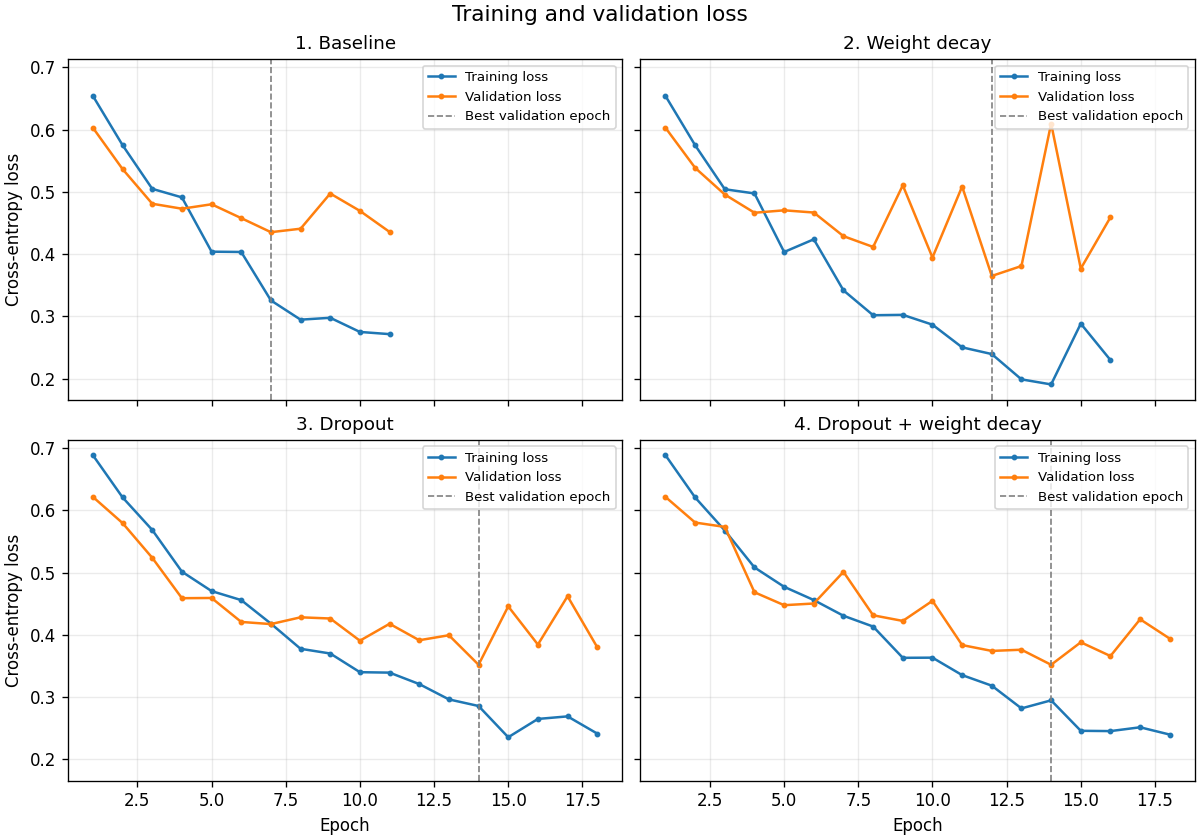

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path
import torch

result_variables = ("baseline_result", "weight_decay_result", "dropout_result", "both_result")
if all(name in globals() for name in result_variables):
    curve_results = {
        "Baseline": baseline_result,
        "Weight Decay": weight_decay_result,
        "Dropout": dropout_result,
        "Both": both_result,
    }
    print("Plotting histories from the current kernel.")
else:
    artifact_path = Path("evaluation_artifacts.pt")
    if not artifact_path.exists():
        raise FileNotFoundError("Run all four experiments or run the export cell after training.")
    curve_results = torch.load(artifact_path, map_location="cpu", weights_only=True)["experiments"]
    print("Plotting histories from the last export: evaluation_artifacts.pt")

experiments_to_plot = [
    ("Baseline", "1. Baseline"),
    ("Weight Decay", "2. Weight decay"),
    ("Dropout", "3. Dropout"),
    ("Both", "4. Dropout + weight decay"),
]
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True, constrained_layout=True)
for ax, (key, title) in zip(axes.flat, experiments_to_plot):
    result = curve_results[key]
    train_losses, val_losses = result["train_losses"], result["val_losses"]
    if not train_losses or len(train_losses) != len(val_losses):
        raise ValueError(f"Invalid loss histories for {title}.")
    epochs = range(1, len(train_losses) + 1)
    ax.plot(epochs, train_losses, marker="o", markersize=2.5, label="Training loss")
    ax.plot(epochs, val_losses, marker="o", markersize=2.5, label="Validation loss")
    ax.axvline(result["best_epoch"], color="gray", linestyle="--", linewidth=1,
               label="Best validation epoch")
    ax.set_title(title, fontsize=11)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="upper right")
for ax in axes[-1, :]:
    ax.set_xlabel("Epoch")
for ax in axes[:, 0]:
    ax.set_ylabel("Cross-entropy loss")
fig.suptitle("Training and validation loss", fontsize=13)
plt.show()


### Interpreting the loss curves

The training losses generally decrease, while validation losses fluctuate and finish above training losses. This gap suggests some overfitting on this split. The pattern differs across experiments: the baseline reaches its lowest validation loss at epoch 7 and ends close to that minimum, whereas weight decay, dropout, and their combination show a clearer rise or fluctuation after their respective best epochs. Early stopping limits later training, but these curves alone do not establish performance on unseen data or prove that a regularization method generalizes better.


## Comparison of the four experiments

These GPU runs use training augmentation and the same stratified holdout split. The saved output reports each run's best epoch by validation loss; the accuracy shown is from that same epoch. The device check reports `cuda`.

| Experiment | Best epoch | Validation loss | Validation accuracy |
| --- | ---: | ---: | ---: |
| Baseline | 7 | 0.4352 | 81.93% |
| Weight decay only | 12 | 0.3649 | 84.74% |
| Dropout only | 14 | 0.3519 | 85.67% |
| Weight decay + dropout | 14 | 0.3519 | 86.60% |

- Dropout only and the combined configuration have the same lowest validation loss to four decimal places (0.3519); the displayed precision does not establish whether their unrounded losses differ.
- The combined configuration has the highest accuracy at its selected epoch (86.60%), compared with 85.67% for dropout only.
- Each regularized configuration has lower validation loss and higher accuracy than the baseline in these saved runs. These comparisons describe the observed results and do not prove a general improvement.
- This is one stratified holdout split with one run per configuration. The same validation set selects the best epoch and supports these comparisons, which can make the results optimistic; sampling and training variation can also affect differences. Repeat runs or use an appropriate 5-fold CV protocol before drawing broader conclusions. The applicable course evaluation route still needs to be confirmed.


## Export results for 03_Model_Evaluation

After running preprocessing and all four experiment cells in this kernel, run the next cell to save the four best model states, metrics, normalized validation split, and training-only normalization statistics. Run it again whenever these results or preprocessing change. Then run the loading cell in 03. Both notebooks should use the project folder as their working directory.


In [19]:
from pathlib import Path
import os
import tempfile
import torch

# Export after running preprocessing and all four experiments in this kernel.
results_to_export = {
    "Baseline": (baseline_result, False),
    "Weight Decay": (weight_decay_result, False),
    "Dropout": (dropout_result, True),
    "Both": (both_result, True),
}
artifact = {
    "format_version": 1,
    "experiments": {},
    # X_val is already normalized using training-set statistics from this split.
    "X_val": torch.from_numpy(X_val.copy()),
    "y_val": torch.from_numpy(y_val.copy()),
    "train_mean": torch.from_numpy(mean.copy()),
    "train_std": torch.from_numpy(std.copy()),
    "split": {"test_size": 0.2, "random_state": 42, "stratified": True},
}
for name, (result, use_dropout) in results_to_export.items():
    artifact["experiments"][name] = {
        "use_dropout": use_dropout,
        "state_dict": {key: value.detach().cpu().clone()
                       for key, value in result["model"].state_dict().items()},
        "best_epoch": int(result["best_epoch"]),
        "best_val_loss": float(result["best_val_loss"]),
        "best_val_accuracy": float(result["best_val_accuracy"]),
        "train_losses": list(result["train_losses"]),
        "val_losses": list(result["val_losses"]),
        "val_accuracies": list(result["val_accuracies"]),
    }

artifact_path = Path("evaluation_artifacts.pt")
fd, temporary_path = tempfile.mkstemp(prefix=".evaluation_", suffix=".pt", dir=artifact_path.parent)
os.close(fd)
try:
    torch.save(artifact, temporary_path)
    os.replace(temporary_path, artifact_path)
finally:
    if os.path.exists(temporary_path):
        os.unlink(temporary_path)
print(f"Saved {len(results_to_export)} experiments and validation data to {artifact_path.resolve()}")


Saved 4 experiments and validation data to the configured output directory.
